In [2]:
# Load in modules
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import numpy as np
import scipy as sp
from scipy.signal import find_peaks
from astropy.io import fits
from matplotlib.colors import LogNorm
from scipy.optimize import curve_fit

# Opening and plotting .fits filetypes

In [138]:
#The file name
#fits_image_filename = 'neon_lamp_2026-10-08_22-24-02__-10.27_5.00s_0000.fits'
fits_image_filename =
#Opening the fits file and extracting the image as a numpy array
neon = fits.open(fits_image_filename)[0].data

print(np.shape(neon))

img = np.squeeze(neon)  # shape ^^

(1039, 1391)


In [3]:
neon

array([[308, 280, 320, ..., 314, 307, 294],
       [296, 337, 306, ..., 326, 312, 323],
       [284, 276, 316, ..., 277, 332, 320],
       ...,
       [289, 294, 333, ..., 312, 308, 312],
       [358, 330, 311, ..., 315, 310, 304],
       [329, 306, 293, ..., 313, 315, 338]], dtype=uint16)

## Plotting with cmap

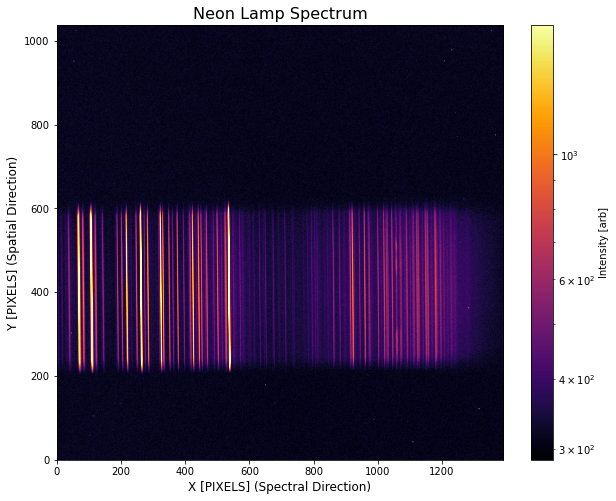

In [139]:
# robust vmin/vmax for LogNorm
pos = img[img > 0] #you are plotting the img defined in the previous cells
vmin = np.percentile(pos, 5) if pos.size else 1
vmax = np.percentile(img, 99.5)

plt.figure(figsize=(10,8))
plt.imshow(
    img,
    cmap='inferno', #change this for different colours!
    aspect='auto',
    origin='lower',
    norm=LogNorm(vmin=vmin, vmax=vmax) #set bounds for intensities
)
#plt.ylim(200,800)
plt.xlabel("X [PIXELS] (Spectral Direction)", size=12)
plt.ylabel("Y [PIXELS] (Spatial Direction)", size=12)
plt.title("Neon Lamp Spectrum", size=16) #For lab reports your figure title goes in the caption
plt.colorbar(label="Intensity [arb]")
plt.show()

## Subtracting an array from an array

Make sure you are using the same integration time as your lamp data.

(1039, 1391)


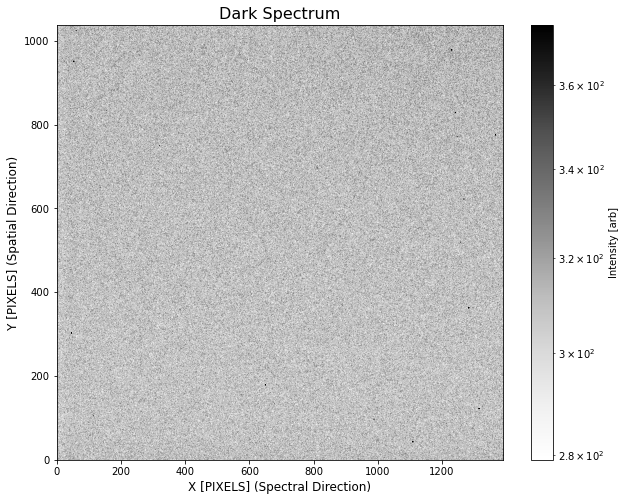

In [7]:
#The file name
# fits_image_filename2 = 'Dark5_2026-10-13_22-18-59__-10.27_2.00s_0000.fits'
fits_image_filename = 

#Opening the fits file and extracting the image as a numpy array
dark = fits.open(fits_image_filename2)[0].data

print(np.shape(dark))

img2 = np.squeeze(dark)  # shape (256, 256)

# robust vmin/vmax for LogNorm
pos = img2[img2 > 0]
vmin = np.percentile(pos, 5) if pos.size else 1
vmax = np.percentile(img, 99.5)

plt.figure(figsize=(10,8))
plt.imshow(
    img2,
    cmap='Greys',
    aspect='auto',
    origin='lower',
    norm=LogNorm(vmin=vmin, vmax=vmax)
)
plt.xlabel("X [PIXELS] (Spectral Direction)", size=12)
plt.ylabel("Y [PIXELS] (Spatial Direction)", size=12)
plt.title("Dark Spectrum", size=16)
plt.colorbar(label="Intensity [arb]")
plt.show()

In [106]:
img3 = img-img2 #calibrated lamp (Obs - Darks)

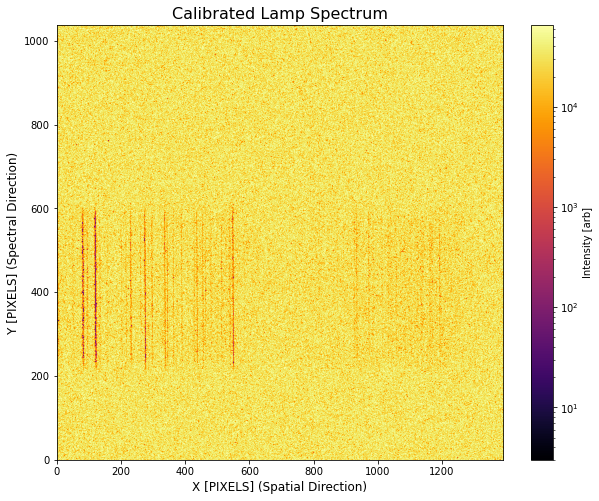

In [107]:
pos = img3
vmin = np.percentile(pos, 5) if pos.size else 1
vmax = np.percentile(img3, 99.5)
plt.figure(figsize=(10,8))
plt.imshow(
    img3,
    cmap='inferno',
    aspect='auto',
    origin='lower',
    norm=LogNorm(vmin=vmin, vmax=vmax)
)
plt.xlabel("X [PIXELS] (Spatial Direction)", size=12)
plt.ylabel("Y [PIXELS] (Spectral Direction)", size=12)
plt.title("Calibrated Lamp Spectrum", size=16)
plt.colorbar(label="Intensity [arb]")
plt.show()

## Extracting a 1D spectrum

In [140]:
y_min, y_max = 450, 470 #choose the size of your slice to optimize S/N
img_slice = img[y_min:y_max,:]

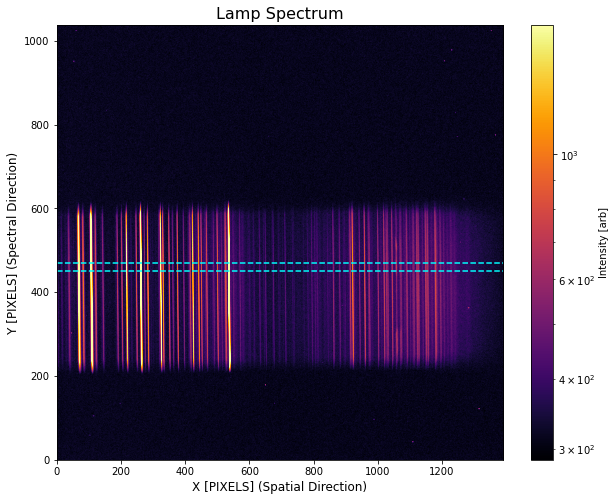

In [141]:
#Same plot as before, just showing the spatial slice we'll be collapsing.
pos = img[img > 0]
vmin = np.percentile(pos, 5) if pos.size else 1
vmax = np.percentile(img, 99.5)
plt.figure(figsize=(10,8))
plt.imshow(
    img,
    cmap='inferno',
    aspect='auto',
    origin='lower',
    norm=LogNorm(vmin=vmin, vmax=vmax)
)
plt.axhline(y_min, color='cyan', linestyle='--')
plt.axhline(y_max, color='cyan', linestyle='--')
plt.xlabel("X [PIXELS] (Spatial Direction)", size=12)
plt.ylabel("Y [PIXELS] (Spectral Direction)", size=12)
plt.title("Lamp Spectrum", size=16)
plt.colorbar(label="Intensity [arb]")
plt.show()

In [213]:
profile_x = np.median(img_slice, axis=0) #taking the median value of intensity across img slice

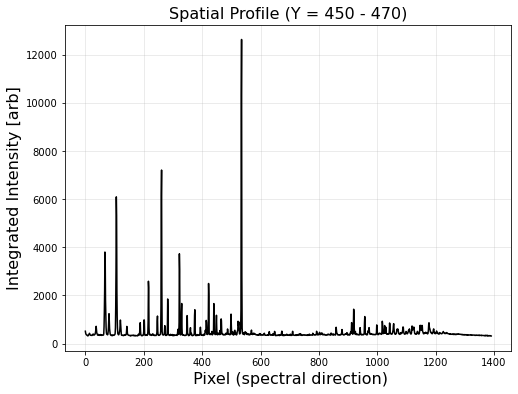

In [262]:
x_pixel = np.arange(len(profile_x)) #creating an array for x-axis (pixels)

plt.figure(figsize=(8,6))
plt.plot(x_pixel, profile_x, color='black') #linear y
#plt.semilogy(x_pixel, profile_x, color='black') #log y
plt.xlabel(" Pixel (spectral direction)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
#Notice the formatting of the string below (%d) calls upon variables
#defined in earlier cells. This avoids silly errors in plot labelling.
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.show()

# Wavelength calibration

In [215]:
def centroid(x, I):
  '''
  Returns the centroid value for a given set of x- and intensity values.

  Input: x: x values, I: intensity values
  Output: centroid value
  '''

  return np.sum(x*I)/np.sum(I)

In [216]:
peaks_2D = sp.signal.find_peaks(profile_x, prominence = 4000)[0] # find peaks and set a prominence we are sensitive to

len(peaks_2D) #helpful to check, if you are only interested in the 3 tallest peaks for examplpe.

3

In [264]:
range_val = 5 #Change this to optimize for your spectrum

centroids_2D = [centroid(x_pixel[peaks_2D[i]-range_val:peaks_2D[i]+range_val], 
                         profile_x[peaks_2D[i]-range_val:peaks_2D[i]+range_val]) 
                for i in range(len(peaks_2D))]
len(centroids_2D) #Sanity check: this is the same as len(peaks_2D)

3

In [271]:
print(peaks_2D, centroids_2D) #These values should be similar but different!

[106 261 535] [106.18069815195072, 260.586029374653, 534.5952290234408]


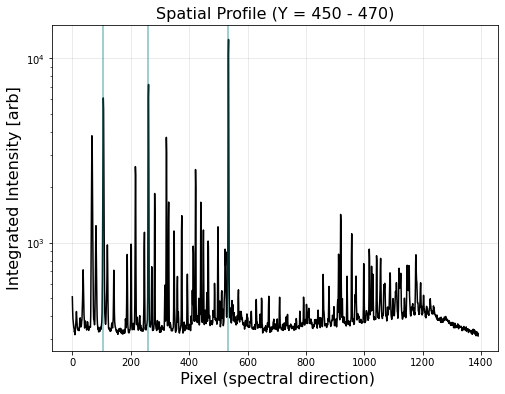

In [309]:
plt.figure(figsize=(8,6))
plt.semilogy(x_pixel, profile_x, color='black')

#Peaks

# plt.plot(x_pixel[peaks_2D], profile_x[peaks_2D], color = 'coral', ls = '',
#          marker = 'x',  ms = 5, label = 'Peaks')

#Centroids (without label):
[plt.axvline(c, color = 'teal', alpha = 0.5) for c in centroids_2D]

#But for ease of labeling I've added an extra step (comment out last line, uncomment next two lines):

# [plt.axvline(c, color = 'teal', alpha = 0.5, label = 'Centroids') if c == centroids_2D[0] 
#  else plt.axvline(c, color = 'teal', alpha = 0.5) for c in centroids_2D]


plt.legend()

plt.xlabel(" Pixel (spectral direction)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.show()

In [274]:
wave = [7032,6678,5852] #attribute 3-4 lines to known Ne/Ar spectrum
len(wave)==len(centroids_2D) #Check that you have the same number of wavelengths as unknown lines

True

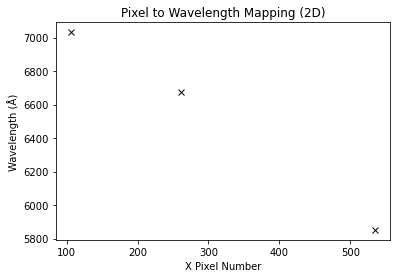

In [278]:
plt.plot(peaks_2D, wave, 'x', color = 'k')
plt.title("Pixel to Wavelength Mapping (2D)")
plt.xlabel("X Pixel Number")
plt.ylabel("Wavelength (Å)")
plt.show()

/Users/aliceirving-hughes/opt/anaconda3/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3369: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)


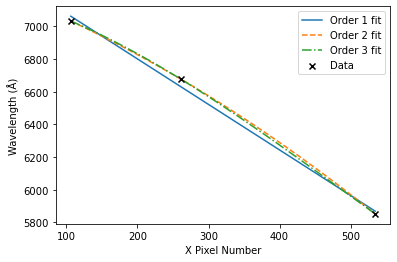

In [277]:
# -----------------------
# Fit polynomials -> param
# -----------------------
p1 = np.polyfit(centroids_2D, wave, 1)   # linear
p2 = np.polyfit(centroids_2D, wave, 2)   # quadratic
p3 = np.polyfit(centroids_2D, wave, 3)   # cubic

# Turn coefficients into functions
f1 = np.poly1d(p1)
f2 = np.poly1d(p2)
f3 = np.poly1d(p3)

# Smooth x-axis for plotting
xfit = np.linspace(np.min(centroids_2D), np.max(centroids_2D), 200)

# -----------------------
# Plot
# -----------------------

plt.plot(xfit, f1(xfit), label="Order 1 fit", linestyle='-')
plt.plot(xfit, f2(xfit), label="Order 2 fit", linestyle='--')
plt.plot(xfit, f3(xfit), label="Order 3 fit", linestyle='-.')

plt.scatter(centroids_2D, wave,label="Data", color = 'k', marker = 'x', zorder=10)

plt.xlabel("X Pixel Number")
plt.ylabel("Wavelength (Å)")
plt.legend()
plt.show()

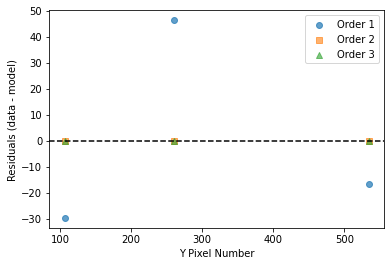

In [224]:
# Model predictions at the SAME x values as the data
y1_model = f1(centroids_2D)
y2_model = f2(centroids_2D)
y3_model = f3(centroids_2D)

# Residuals
resid1 = wave - y1_model
resid2 = wave - y2_model
resid3 = wave - y3_model


plt.axhline(0, color = 'k', linestyle="--")  # zero line
plt.scatter(centroids_2D, resid1, marker='o', label='Order 1', alpha = 0.7)
plt.scatter(centroids_2D, resid2, marker='s', label='Order 2', alpha = 0.6)
plt.scatter(centroids_2D, resid3, marker='^', label='Order 3', alpha = 0.6)

plt.xlabel("Y Pixel Number")
plt.ylabel("Residuals (data - model)")
plt.legend()
plt.show()

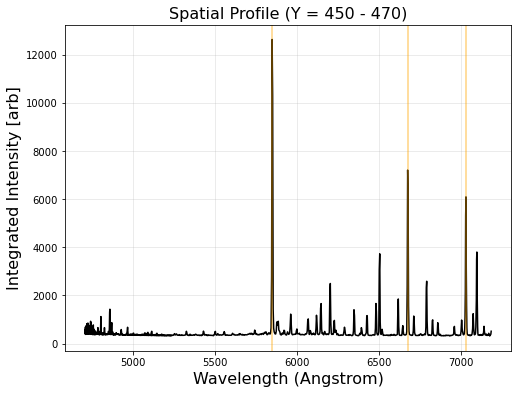

In [225]:
plt.figure(figsize=(8,6))
plt.plot(f3(x_pixel), profile_x, color='black') #choose one of the functions (f1, f2, f3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Known') for c in wave]
plt.xlabel("Wavelength (Angstrom)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
plt.show()

# Fitting other lines
Make sure your model works well across the whole band. In total, you should be able to assign 10-15 lines, taking care to cover the whole domain.

There are two approaches to this:
1. By eye, locate prominent lines in your data, and search for them in the NIST catalog. (You can filter NIST lines by frequency range to make this easier).
2. Look for strong lines in the NIST catalog and see if they appear in your data.

In [226]:
lines = [6074,6069,6506]

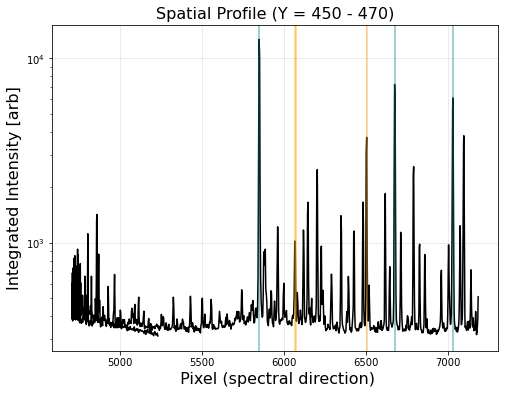

In [315]:
plt.figure(figsize=(8,6))
plt.semilogy(f3(x_pixel), profile_x, color='black')
plt.xlabel(" Pixel (spectral direction)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)
[plt.axvline(c, color = 'orange', alpha = 0.5, label = 'Additional lines') for c in lines]
[plt.axvline(c, color = 'teal', alpha = 0.5, label = 'Initial guesses') for c in wave]
plt.show()

In [ ]:
#Locating the index (a) of the known wavelength lines[1], and the centroid around that wavelength (b)
a = np.argmin(np.abs(f3(x_pixel)-lines[1]))
rng = 5
b = centroid(f3(x_pixel)[a-rng:a+rng],profile_x[a-rng:a+rng])

In [ ]:
b, lines[1] #how close are they? Within 1 Å?

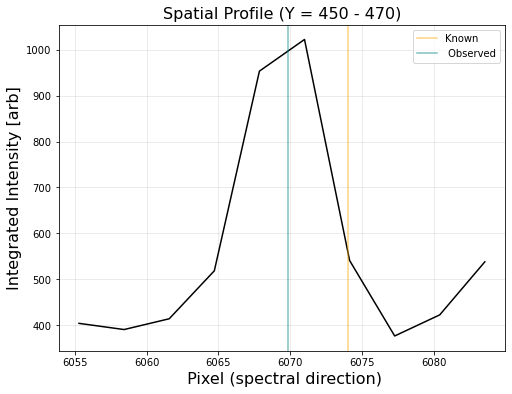

In [306]:
plt.figure(figsize=(8,6))
plt.plot(f3(x_pixel)[a-rng:a+rng], profile_x[a-rng:a+rng], color='black')
# plt.axvline(lines[0], color = 'orange', alpha = 0.5, label = 'Known')
# plt.axvline(b, color = 'teal', alpha = 0.5, label = 'Centroid')
# plt.legend()
plt.xlabel(" Pixel (spectral direction)", size=16)
plt.ylabel("Integrated Intensity [arb]", size=16)
plt.title("Spatial Profile (Y = %d - %d)" %(y_min, y_max), size=16)
plt.grid(alpha=0.3)

plt.show()